# <center>Geometric Brownian Motion Formel</center>

<center><h4>formel for GBM:</h4>
<br>
<img src="https://investexcel.net/wp-content/uploads/2011/10/driftUncertainty1.png">
<br>
<p>μ(mu): expected yearly return</p>
<br>
<p>σ(sigma): standart deviation</p>
<br>
<p>ε(epsilon): Margin of error</p>
<br>
<p>dt/∆t: 1/Terms per year</p>
</center>

In [7]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

In [8]:
def gbm(n_years=5, mu=0.07, sigma=0.15, steps_pr_year= 12, n_scenarios=100, initial_value=100):
    dt=1/steps_pr_year
    n_steps = int(n_years*steps_pr_year)
    returns=np.random.normal(loc=(((1+mu)**dt)), scale=(sigma*np.sqrt(dt)), size=(n_steps, n_scenarios))
    rets=pd.concat([pd.DataFrame(np.ones((1, n_scenarios))), pd.DataFrame(returns)], ignore_index=True)
    return rets.cumprod()*initial_value

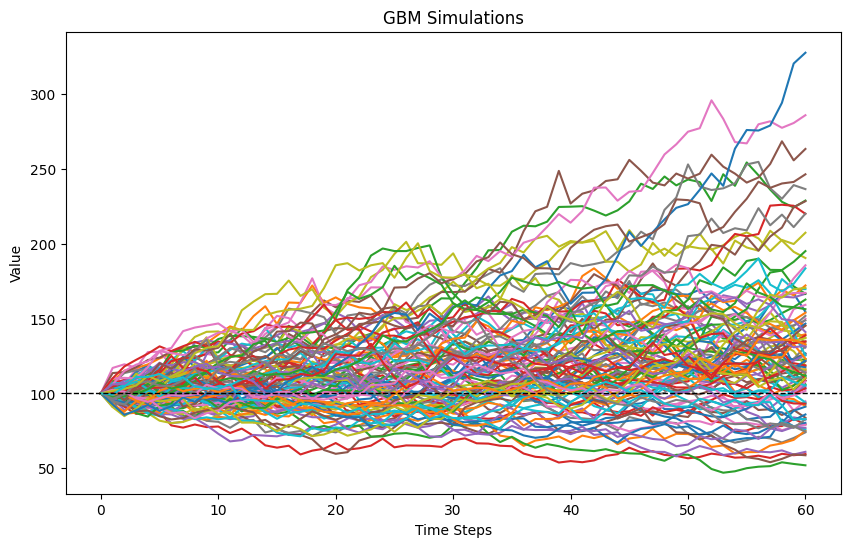

In [9]:
plt.figure(figsize=(10, 6))
plt.plot(gbm())
plt.axhline(100, color='black', lw=1, ls='--')
plt.title('GBM Simulations')
plt.xlabel('Time Steps')
plt.ylabel('Value')
plt.show()

<center><h2>Interactive Plotting</h2></center>

In [10]:
import ipywidgets as widgets
import matplotlib.pyplot as plt

In [11]:
def interactive_gbm(n_years=5, mu=0.07, sigma=0.15, steps_pr_year= 12, n_scenarios=100, initial_value=100):
    rets=gbm(n_years=n_years, mu=mu, sigma=sigma, steps_pr_year=steps_pr_year, n_scenarios=n_scenarios, initial_value=initial_value)
    terminal_value = rets.iloc[-1]

    fig, (returns_ax, terminal_value_ax) = plt.subplots(nrows=1, ncols=2, sharey=all, gridspec_kw={'width_ratios':[3, 1]}, figsize=(12, 6))
    plt.subplots_adjust(wspace=0)
    rets.plot(legend=False, ax=returns_ax, color='skyblue', alpha=0.8, lw=1)
    returns_ax.set_title('GBM Returns')
    returns_ax.axhline(y=initial_value, color='black', lw=2, ls='--')
    terminal_value.plot(kind='hist', bins=50, ax=terminal_value_ax, orientation='horizontal', edgecolor='white')
    terminal_value_ax.set_title('Terminal Value Distribution')
    print(f"Average return: {(terminal_value.mean()/initial_value-1)*100:.2f}%")
    print(f"Expected return: {((1+mu)**n_years-1)*100:.2f}%")

In [12]:
widgets.interactive(interactive_gbm, n_years=(1, 15), mu=(-0.05, 0.25, 0.01), sigma=(0, 0.3, 0.01), steps_pr_year=(12, 252, 4), n_scenarios=(1, 1000), initial_value=(1, 1000, 1))

interactive(children=(IntSlider(value=5, description='n_years', max=15, min=1), FloatSlider(value=0.07, descri…